In [ ]:
---
title: "Do English speakers consistently get top marks on the English language test?"
authors:
  - name: "Shiyi Yuan"
    affiliation: "UC Berkeley"
exports:
  - format: pdf
    template: arxiv_two_column
    output: exports/IELTS_test_Q1.pdf
---

In [4]:
demo_by_first_language <- readr::read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-08-18/demo_by_first_language.csv')
demo_by_nationality <- readr::read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-08-18/demo_by_nationality.csv')
demo_by_reasons <- readr::read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-08-18/demo_by_reasons.csv')
performance_by_first_language <- readr::read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-08-18/performance_by_first_language.csv')
performance_by_nationality <- readr::read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-08-18/performance_by_nationality.csv')

Rows: 2880 Columns: 5


── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): type, language, band, year
dbl (1): percent



ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Rows: 2832 Columns: 5


── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): type, nationality, band, year
dbl (1): percent



ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


... (5 outputs left out)


ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Rows: 1180 Columns: 5


── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): type, nationality, part, year
dbl (1): score



ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [5]:
perf <- performance_by_first_language
demo <- demo_by_first_language

In [6]:
head(perf)

type,language,part,score,year
<chr>,<chr>,<chr>,<dbl>,<chr>
Academic,Arabic,listening,5.703570,2024-2025
Academic,Arabic,reading,6.099949,2024-2025
Academic,Arabic,writing,5.539552,2024-2025
Academic,Arabic,speaking,6.215372,2024-2025
Academic,Arabic,overall,5.953004,2024-2025
Academic,Azeri,listening,6.581207,2024-2025


In [9]:
unique(perf$year)

[1] "2024-2025" "2023-2024" "2022-2023"

In [17]:
top10 <- perf |>
    filter(part == "overall", type == "Academic") |>
    filter(year == "2024-2025") |>
    arrange(desc(score)) |>
    head(10)   
top10

type,language,part,score,year
<chr>,<chr>,<chr>,<dbl>,<chr>
Academic,German,overall,7.601557,2024-2025
Academic,Greek,overall,7.240173,2024-2025
Academic,English,overall,7.057243,2024-2025
Academic,Italian,overall,7.004815,2024-2025
Academic,Portuguese,overall,6.916339,2024-2025
Academic,Filipino,overall,6.810798,2024-2025
Academic,Hindi,overall,6.758006,2024-2025
Academic,French,overall,6.754026,2024-2025
Academic,Marathi,overall,6.740228,2024-2025


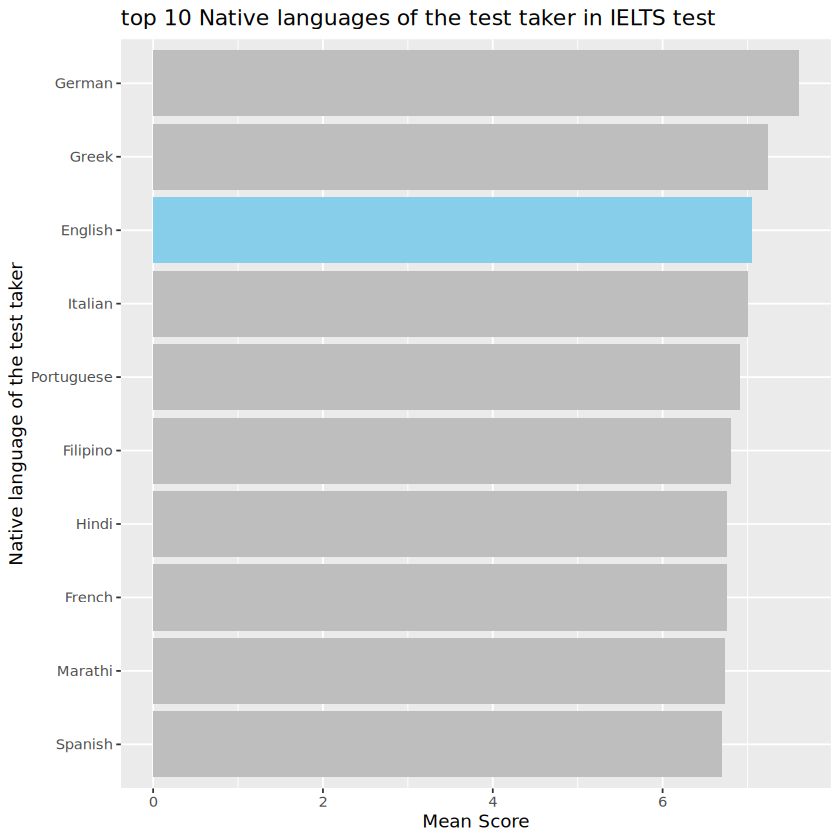

In [20]:
library(tidyverse)

ggplot(top10, aes(x = score, y = reorder(language, score), fill = language == "English"))+
    geom_col()+
    scale_fill_manual(values = c("grey", "skyblue"), guide = "none") +
    labs(x = "Mean Score", y = "Native language of the test taker" , title = "top 10 Native languages of the test taker in IELTS test")